# **A1: Sentiment Analysis of IMDb Movie Reviews Using Machine Learning**

Movie reviews contain valuable information about viewers' opinions. In this project, we will build a machine learning model to classify IMDb movie reviews as Positive or Negative based on the review text. We will preprocess the text, extract features, train multiple classifiers, and compare their performance.

In [55]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string

# NLP libraries
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

# ML libraries
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [56]:
# Download NLTK Resources

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

**Task 1: Data Exploration**

In [57]:
# Load the IMDb Movie Reviews dataset
df = pd.read_csv("IMDB_Dataset.csv")
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [58]:
# Display the first five records
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [59]:
# Check the number of reviews
print("Number of reviews:", len(df), "\n")

# Check the number of sentiment labels
print(df['sentiment'].value_counts())

Number of reviews: 50000 

sentiment
positive    25000
negative    25000
Name: count, dtype: int64


In [60]:
# Check Missing Values
print(df.isnull().sum())

review       0
sentiment    0
dtype: int64


In [61]:
# Check Duplicates
print(df.duplicated().sum())

418


In [62]:
# Remove Duplicates
df = df.drop_duplicates()

print("After removing duplicates:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

After removing duplicates: (49582, 2)
Remaining duplicates: 0


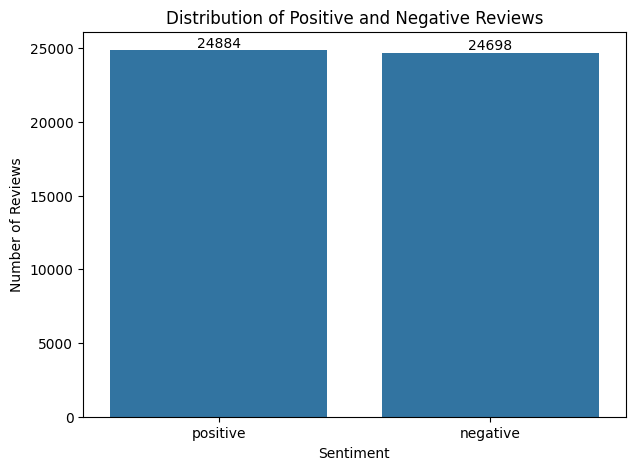

In [63]:
# Plot the distribution of positive and negative reviews.
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x='sentiment'
)
# Add the count labels to each bar
for container in ax.containers:
    ax.bar_label(container)
plt.title('Distribution of Positive and Negative Reviews')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')

plt.show()

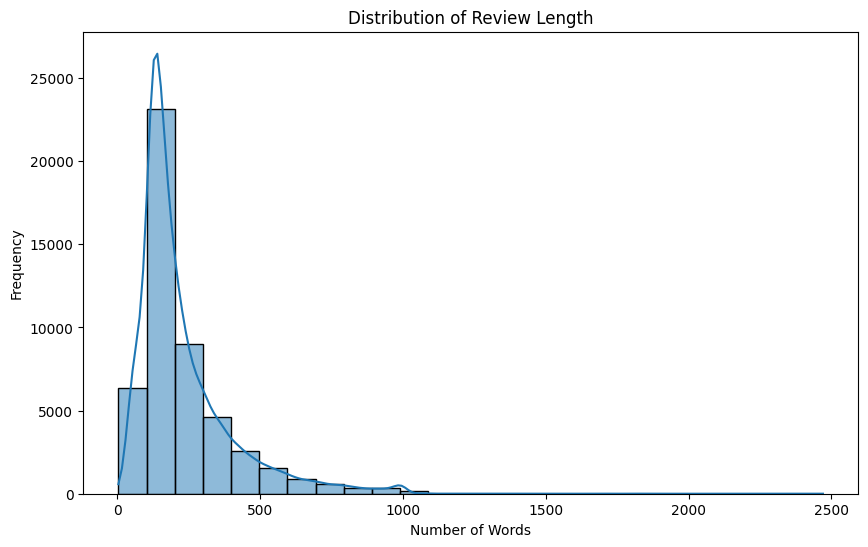

In [64]:
# word count
df['word_count'] = df['review'].apply(lambda x: len(x.split()))

df[['review', 'sentiment', 'word_count']].head()

# Display the review length distribution.
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='word_count',
    bins=25,
    kde=True
)

plt.title('Distribution of Review Length')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')

plt.show()

**Task 2: Text Preprocessing**

In [65]:
# Review Preview
print("Positive Review:")
print(df[df['sentiment'] == 'positive']['review'].iloc[0])

print("\n" + "="*80 + "\n")

print("Negative Review:")
print(df[df['sentiment'] == 'negative']['review'].iloc[0])

Positive Review:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show 

In [66]:
# Stopwords
stop_words = set(stopwords.words('english'))

# Preserve important negation words
negation_words = {'not', 'no', 'nor', 'never'}

# Remove negation words from the stopword list (it is done because If "not" is removed as a stopword from a review(movie is not good), we could end up with a review being positive instead of negative)
stop_words = stop_words - negation_words

# Lemmatizer
lemmatizer = WordNetLemmatizer()


def preprocess_text(text):

    # Convert to lowercase
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r'<.*?>', ' ', text)

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', ' ', text)

    # Remove punctuation and special characters
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)

    # Tokenization
    tokens = word_tokenize(text)

    # Remove stopwords and very short tokens
    tokens = [
        word for word in tokens
        if word not in stop_words and len(word) > 1
    ]

    # Lemmatization
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    # Join tokens back into a single string
    cleaned_text = ' '.join(tokens)

    return cleaned_text

In [67]:
# Applying preprocessing to one review
sample_review = df['review'].iloc[0]

cleaned_sample = preprocess_text(sample_review)

print("ORIGINAL REVIEW:")
print(sample_review)

print("\n" + "="*80 + "\n")

print("CLEANED REVIEW:")
print(cleaned_sample)

ORIGINAL REVIEW:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show 

In [68]:
# Apply Preprocessing to the Whole Dataset
df['cleaned_review'] = df['review'].apply(preprocess_text)

In [69]:
# Reviews Preview after preprocessing
print(df[['review', 'cleaned_review', 'sentiment']].head(5))


                                              review  \
0  One of the other reviewers has mentioned that ...   
1  A wonderful little production. <br /><br />The...   
2  I thought this was a wonderful way to spend ti...   
3  Basically there's a family where a little boy ...   
4  Petter Mattei's "Love in the Time of Money" is...   

                                      cleaned_review sentiment  
0  one reviewer mentioned watching oz episode hoo...  positive  
1  wonderful little production filming technique ...  positive  
2  thought wonderful way spend time hot summer we...  positive  
3  basically family little boy jake think zombie ...  negative  
4  petter mattei love time money visually stunnin...  positive  


**Task 3: Feature Extraction**

In [70]:
# feature Extraction
X = df['cleaned_review']
y = df['sentiment']



In [71]:
# Convert sentiments to Numerical Labels (0 and 1)
y = y.map({
    'negative': 0,
    'positive': 1
})


In [72]:
# create Train-Test Split.
# It is done in advance because the vectorizer learns the vocabulary from the data. If it sees the test set during fitting, it results in data leakage.
# Stratify=y ensures that the training and testing sets contain the same positive/negative proportion.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

In [75]:
# Convert the cleaned text into numerical features using Bag of Words (how frequently words/features occur).

bow_vectorizer = CountVectorizer(
    max_features=50000,
    ngram_range=(1, 2) # we are considering bigrams here or two word combinations ("not good", "waste money") to capture true meaning
)

X_train_bow = bow_vectorizer.fit_transform(X_train)
X_test_bow = bow_vectorizer.transform(X_test)

BoW Training Matrix Shape: (39665, 50000)
BoW Testing Matrix Shape: (9917, 50000)


In [78]:
# Convert the cleaned text into TF-IDF features.
# TF-IDF not only considers how frequently a word appears in a particular document but also how commonly that word appears across the entire set of documents.

tfidf_vectorizer = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

TF-IDF Training Matrix Shape: (39665, 50000)
TF-IDF Testing Matrix Shape: (9917, 50000)


In [81]:
# Compare the dimensions of the generated feature matrices.

feature_comparison = pd.DataFrame({
    'Feature Method': ['Bag of Words', 'TF-IDF'],
    'Training Samples': [
        X_train_bow.shape[0],
        X_train_tfidf.shape[0]
    ],
    'Testing Samples': [
        X_test_bow.shape[0],
        X_test_tfidf.shape[0]
    ],
    'Number of Features': [
        X_train_bow.shape[1],
        X_train_tfidf.shape[1]
    ]
})

feature_comparison

,Feature Method,Training Samples,Testing Samples,Number of Features
0,Bag of Words,39665,9917,50000
1,TF-IDF,39665,9917,50000


**Task 5: Model Building**

In [83]:
# Train Multinomial Naive Bayes.

nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

y_pred_nb = nb_model.predict(X_test_tfidf)

print("Multinomial Naive Bayes trained successfully.")

print(y_pred_nb[:20])

Multinomial Naive Bayes trained successfully.
[0 1 1 0 0 1 0 0 1 0 0 1 1 0 1 0 1 0 1 0]


In [84]:
# Train Logistic Regression.
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_tfidf, y_train)

y_pred_lr = lr_model.predict(X_test_tfidf)

print("Logistic Regression trained successfully.")

print(y_pred_lr[:20])

Logistic Regression trained successfully.
[0 1 1 0 0 1 0 0 1 0 0 1 1 0 1 0 1 0 1 0]


In [85]:
# Train Support Vector Machine (SVM).
svm_model = LinearSVC(
    random_state=42
)

svm_model.fit(X_train_tfidf, y_train)

y_pred_svm = svm_model.predict(X_test_tfidf)

print("SVM trained successfully.")

print(y_pred_svm[:20])

SVM trained successfully.
[0 1 1 1 0 1 0 0 1 0 0 1 1 0 1 0 1 1 1 0]


**Task 5: Model Evaluation**

In [88]:
# Evaluate each model using Accuracy, Precision, Recall, F1-score, and Confusion Matrix.
# Model EValuation Function
def evaluate_model(model_name, y_true, y_pred):

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(y_true, y_pred)

    recall = recall_score(y_true, y_pred)

    f1 = f1_score(y_true, y_pred)

    print("=" * 60)
    print(model_name)
    print("=" * 60)

    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-score : {f1:.4f}")

    print("\nClassification Report:")
    print(
        classification_report(
            y_true,
            y_pred,
            target_names=['Negative', 'Positive']
        )
    )

    return accuracy, precision, recall, f1

In [89]:
# Evaluate Naive Bayes
nb_metrics = evaluate_model(
    "Multinomial Naive Bayes",
    y_test,
    y_pred_nb
)

Multinomial Naive Bayes
Accuracy : 0.8861
Precision: 0.8810
Recall   : 0.8937
F1-score : 0.8873

Classification Report:
              precision    recall  f1-score   support

    Negative       0.89      0.88      0.88      4940
    Positive       0.88      0.89      0.89      4977

    accuracy                           0.89      9917
   macro avg       0.89      0.89      0.89      9917
weighted avg       0.89      0.89      0.89      9917



In [90]:
# Evaluate Logistic Regression
lr_metrics = evaluate_model(
    "Logistic Regression",
    y_test,
    y_pred_lr
)

Logistic Regression
Accuracy : 0.9008
Precision: 0.8908
Recall   : 0.9144
F1-score : 0.9024

Classification Report:
              precision    recall  f1-score   support

    Negative       0.91      0.89      0.90      4940
    Positive       0.89      0.91      0.90      4977

    accuracy                           0.90      9917
   macro avg       0.90      0.90      0.90      9917
weighted avg       0.90      0.90      0.90      9917



In [91]:
# Evaluate SVM
svm_metrics = evaluate_model(
    "Support Vector Machine",
    y_test,
    y_pred_svm
)

Support Vector Machine
Accuracy : 0.9027
Precision: 0.8983
Recall   : 0.9090
F1-score : 0.9036

Classification Report:
              precision    recall  f1-score   support

    Negative       0.91      0.90      0.90      4940
    Positive       0.90      0.91      0.90      4977

    accuracy                           0.90      9917
   macro avg       0.90      0.90      0.90      9917
weighted avg       0.90      0.90      0.90      9917



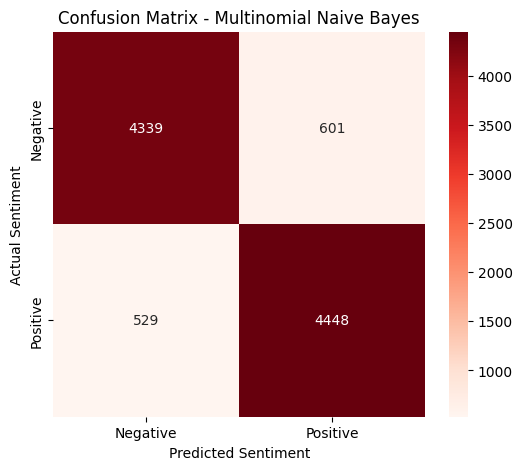

In [104]:
# Naive Bayes Confusion Matrix
cm_nb = confusion_matrix(y_test, y_pred_nb)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt='d',
    cmap='Reds',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.title('Confusion Matrix - Multinomial Naive Bayes')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')

plt.show()

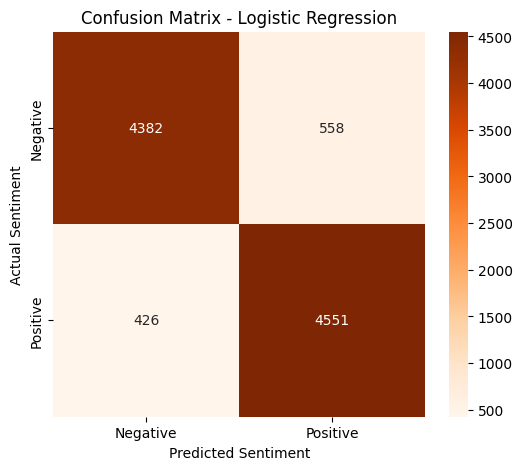

In [108]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')

plt.show()

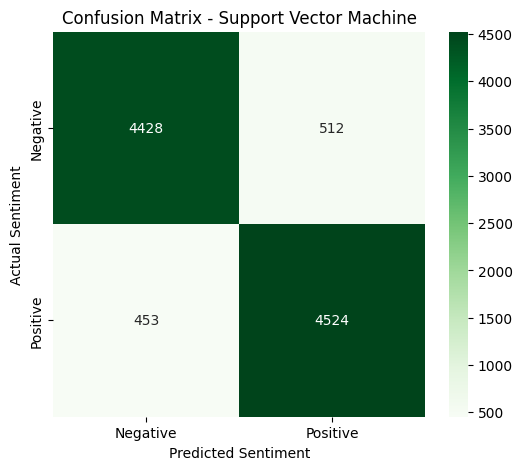

In [94]:
cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.title('Confusion Matrix - Support Vector Machine')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')

plt.show()

**Task 6: Performance Comparison**

In [95]:
# performance comparisions of the 3 models

comparison_df = pd.DataFrame({
    'Model': [
        'Multinomial Naive Bayes',
        'Logistic Regression',
        'Support Vector Machine'
    ],
    'Accuracy': [
        nb_metrics[0],
        lr_metrics[0],
        svm_metrics[0]
    ],
    'Precision': [
        nb_metrics[1],
        lr_metrics[1],
        svm_metrics[1]
    ],
    'Recall': [
        nb_metrics[2],
        lr_metrics[2],
        svm_metrics[2]
    ],
    'F1-score': [
        nb_metrics[3],
        lr_metrics[3],
        svm_metrics[3]
    ]
})

comparison_df

,Model,Accuracy,Precision,Recall,F1-score
0,Multinomial Naive Bayes,0.886054,0.880967,0.893711,0.887293
1,Logistic Regression,0.900776,0.890781,0.914406,0.902439
2,Support Vector Machine,0.902692,0.898332,0.908981,0.903625


**Based on your results, Support Vector Machine is the best-performing classifier overall having the highest F1-score. Logistic Regression is equally good as the difference is minimal.**

**Task 7: Prediction on New Reviews**

In [98]:
# Prediction on unseen reviews
new_reviews = [
    "The movie was fantastic with brilliant acting and an emotional story.",
    "I wasted my time watching this movie. The plot was boring and predictable.",
    "The cinematography was beautiful, but the story was average.",
    "An excellent thriller that kept me engaged until the very end.",
    "Poor acting and weak screenplay made this film disappointing."
    ]

['The movie was fantastic with brilliant acting and an emotional story.',
 'I wasted my time watching this movie. The plot was boring and predictable.',
 'The cinematography was beautiful, but the story was average.',
 'An excellent thriller that kept me engaged until the very end.',
 'Poor acting and weak screenplay made this film disappointing.']

In [99]:
# New Reviews Preprocessing
cleaned_new_reviews = [
    preprocess_text(review)
    for review in new_reviews
]

for original, cleaned in zip(new_reviews, cleaned_new_reviews):
    print("Original:")
    print(original)
    print("\nCleaned:")
    print(cleaned)
    print("\n" + "="*80 + "\n")

Original:
The movie was fantastic with brilliant acting and an emotional story.

Cleaned:
movie fantastic brilliant acting emotional story


Original:
I wasted my time watching this movie. The plot was boring and predictable.

Cleaned:
wasted time watching movie plot boring predictable


Original:
The cinematography was beautiful, but the story was average.

Cleaned:
cinematography beautiful story average


Original:
An excellent thriller that kept me engaged until the very end.

Cleaned:
excellent thriller kept engaged end


Original:
Poor acting and weak screenplay made this film disappointing.

Cleaned:
poor acting weak screenplay made film disappointing




In [100]:
# convert cleaned reviews to TF-IDF
new_reviews_tfidf = tfidf_vectorizer.transform(cleaned_new_reviews)

print("New reviews TF-IDF shape:", new_reviews_tfidf.shape)

New reviews TF-IDF shape: (5, 50000)


In [101]:
# Make Predictions
predictions = svm_model.predict(new_reviews_tfidf)

print(predictions)

[1 0 1 1 0]


In [102]:
predicted_sentiments = [
    'Positive' if prediction == 1 else 'Negative'
    for prediction in predictions
]

results_df = pd.DataFrame({
    'Original Review': new_reviews,
    'Predicted Sentiment': predicted_sentiments
})

results_df

,Original Review,Predicted Sentiment
0,The movie was fantastic with brilliant acting ...,Positive
1,I wasted my time watching this movie. The plot...,Negative
2,"The cinematography was beautiful, but the stor...",Positive
3,An excellent thriller that kept me engaged unt...,Positive
4,Poor acting and weak screenplay made this film...,Negative
